In [1]:
print("Araştırma Projemize Hoş Geldiniz!")
print("Çalışma Modellerinin Çalışanlar Üzerindeki Etkisi")

Araştırma Projemize Hoş Geldiniz!
Çalışma Modellerinin Çalışanlar Üzerindeki Etkisi


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Veri analiz araçlarımız hazır!")
print("Araştırmamıza başlayabiliriz.")

Veri analiz araçlarımız hazır!
Araştırmamıza başlayabiliriz.


In [3]:
veriler = pd.DataFrame(columns=[
    "Calisma_Modeli",
    "Performans",
    "Is_Ozel_Hayat_Dengesi",
    "Isten_Ayrilma"
])

print("Araştırma veri tablomuz oluşturuldu!")
display(veriler)

Araştırma veri tablomuz oluşturuldu!


,Calisma_Modeli,Performans,Is_Ozel_Hayat_Dengesi,Isten_Ayrilma


In [4]:
print("Araştırma veri seti hazırlık aşamasındayız.")
print("Çalışma modelleri: Uzaktan, Hibrit, Ofisten")
print("Araştırma değişkenleri: Performans, İş-Özel Hayat Dengesi, Attrition")

Araştırma veri seti hazırlık aşamasındayız.
Çalışma modelleri: Uzaktan, Hibrit, Ofisten
Araştırma değişkenleri: Performans, İş-Özel Hayat Dengesi, Attrition


In [6]:
url = "https://huggingface.co/datasets/nprak26/remote-worker-productivity/resolve/main/remote_work_productivity.csv"

veri = pd.read_csv(url)

print("Veri başarıyla yüklendi!")
print("Veri boyutu:", veri.shape)

display(veri.head())

Veri başarıyla yüklendi!
Veri boyutu: (1500, 30)


,Employee_ID,Age,Years_Experience,WFH_Days_Per_Week,Gender,Education_Level,Marital_Status,Has_Children,Location_Type,Department,...,Quality_Score,Innovation_Score,Efficiency_Rating,Meetings_Per_Week,Commute_Time_Minutes,Job_Satisfaction,Stress_Level,Work_Life_Balance,Survey_Date,Response_Quality
0,EMP0001,39,10,2,Female,Associate Degree,Married,Yes,Urban,Product,...,58.1,52.1,72.1,4,48,55.9,6,8,2024-04-05,Medium
1,EMP0002,33,4,5,Female,Master Degree,Married,No,Urban,Customer Success,...,93.3,77.9,89.5,12,0,96.1,3,8,2024-01-29,High
2,EMP0003,40,3,3,Male,PhD,Single,Yes,Rural,Operations,...,84.7,63.2,95.0,15,24,90.4,5,6,2024-01-18,High
3,EMP0004,48,14,3,Male,Bachelor Degree,Married,Yes,Urban,Finance,...,67.8,82.5,95.0,8,8,100.0,10,5,2024-04-18,High
4,EMP0005,32,6,5,Male,High School,Divorced,Yes,Rural,Engineering,...,86.4,67.5,95.0,10,0,100.0,3,4,2024-02-19,High


In [7]:
print("VERİ SETİMİZDEKİ SÜTUNLAR")

for sutun in veri.columns:
    print("-", sutun)

print("\nToplam çalışan kaydı:", len(veri))
print("Toplam değişken sayısı:", len(veri.columns))

VERİ SETİMİZDEKİ SÜTUNLAR
- Employee_ID
- Age
- Years_Experience
- WFH_Days_Per_Week
- Gender
- Education_Level
- Marital_Status
- Has_Children
- Location_Type
- Department
- Job_Level
- Company_Size
- Industry
- Home_Office_Quality
- Internet_Speed_Category
- Work_Hours_Per_Week
- Manager_Support_Level
- Team_Collaboration_Frequency
- Productivity_Score
- Task_Completion_Rate
- Quality_Score
- Innovation_Score
- Efficiency_Rating
- Meetings_Per_Week
- Commute_Time_Minutes
- Job_Satisfaction
- Stress_Level
- Work_Life_Balance
- Survey_Date
- Response_Quality

Toplam çalışan kaydı: 1500
Toplam değişken sayısı: 30


In [8]:
print("TÜM SÜTUNLAR")

for i, sutun in enumerate(veri.columns, start=1):
    print(i, "-", sutun)

print("\nVeri boyutu:", veri.shape)

TÜM SÜTUNLAR
1 - Employee_ID
2 - Age
3 - Years_Experience
4 - WFH_Days_Per_Week
5 - Gender
6 - Education_Level
7 - Marital_Status
8 - Has_Children
9 - Location_Type
10 - Department
11 - Job_Level
12 - Company_Size
13 - Industry
14 - Home_Office_Quality
15 - Internet_Speed_Category
16 - Work_Hours_Per_Week
17 - Manager_Support_Level
18 - Team_Collaboration_Frequency
19 - Productivity_Score
20 - Task_Completion_Rate
21 - Quality_Score
22 - Innovation_Score
23 - Efficiency_Rating
24 - Meetings_Per_Week
25 - Commute_Time_Minutes
26 - Job_Satisfaction
27 - Stress_Level
28 - Work_Life_Balance
29 - Survey_Date
30 - Response_Quality

Veri boyutu: (1500, 30)


In [9]:
print("ARAŞTIRMADA KULLANACAĞIMIZ VERİLER")

display(veri[[
    "WFH_Days_Per_Week",
    "Productivity_Score",
    "Work_Life_Balance"
]].head(10))

ARAŞTIRMADA KULLANACAĞIMIZ VERİLER


,WFH_Days_Per_Week,Productivity_Score,Work_Life_Balance
0,2,52.2,8
1,5,81.5,8
2,3,82.2,6
3,3,75.6,5
4,5,98.0,4
5,4,62.0,5
6,2,66.2,3
7,0,77.2,5
8,4,73.8,7
9,4,72.4,4


In [10]:
print("Haftalık evden çalışma günleri:")

print(sorted(veri["WFH_Days_Per_Week"].unique()))

print("\nHer gün değerinden kaç çalışan var?")
print(veri["WFH_Days_Per_Week"].value_counts().sort_index())

Haftalık evden çalışma günleri:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Her gün değerinden kaç çalışan var?
WFH_Days_Per_Week
0    137
1    168
2    264
3    330
4    405
5    196
Name: count, dtype: int64


In [12]:
def calisma_modeli(gun):
    if gun == 0:
        return "Ofisten"
    elif gun == 5:
        return "Uzaktan"
    else:
        return "Hibrit"

veri["Calisma_Modeli"] = veri["WFH_Days_Per_Week"].apply(calisma_modeli)

print("ÇALIŞMA MODELLERİNE GÖRE ÇALIŞAN SAYILARI")

print(veri["Calisma_Modeli"].value_counts())

display(veri[[
    "Calisma_Modeli",
    "Productivity_Score",
    "Work_Life_Balance"
]].head(10))

ÇALIŞMA MODELLERİNE GÖRE ÇALIŞAN SAYILARI
Calisma_Modeli
Hibrit     1167
Uzaktan     196
Ofisten     137
Name: count, dtype: int64


,Calisma_Modeli,Productivity_Score,Work_Life_Balance
0,Hibrit,52.2,8
1,Uzaktan,81.5,8
2,Hibrit,82.2,6
3,Hibrit,75.6,5
4,Uzaktan,98.0,4
5,Hibrit,62.0,5
6,Hibrit,66.2,3
7,Ofisten,77.2,5
8,Hibrit,73.8,7
9,Hibrit,72.4,4


ÇALIŞMA MODELİNE GÖRE ORTALAMA PERFORMANS


,Productivity_Score
Calisma_Modeli,
Hibrit,83.34
Ofisten,80.86
Uzaktan,83.22


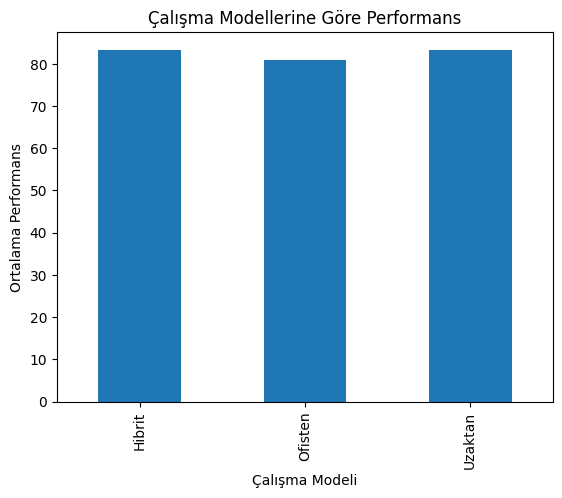

In [13]:
performans = veri.groupby("Calisma_Modeli")["Productivity_Score"].mean()

print("ÇALIŞMA MODELİNE GÖRE ORTALAMA PERFORMANS")
display(performans.round(2))

performans.plot(kind="bar", title="Çalışma Modellerine Göre Performans")
plt.xlabel("Çalışma Modeli")
plt.ylabel("Ortalama Performans")
plt.show()

ÇALIŞMA MODELİNE GÖRE İŞ-ÖZEL HAYAT DENGESİ


,Work_Life_Balance
Calisma_Modeli,
Hibrit,6.25
Ofisten,6.24
Uzaktan,6.06


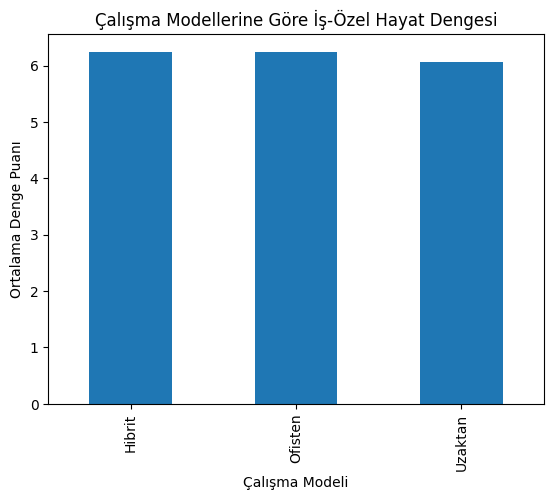

In [14]:
denge = veri.groupby("Calisma_Modeli")["Work_Life_Balance"].mean()

print("ÇALIŞMA MODELİNE GÖRE İŞ-ÖZEL HAYAT DENGESİ")
display(denge.round(2))

denge.plot(kind="bar", title="Çalışma Modellerine Göre İş-Özel Hayat Dengesi")

plt.xlabel("Çalışma Modeli")
plt.ylabel("Ortalama Denge Puanı")
plt.show()

In [15]:
print("Araştırmanın ilk iki analizi tamamlandı.")
print("Sıradaki analiz: İşten Ayrılma (Attrition)")

Araştırmanın ilk iki analizi tamamlandı.
Sıradaki analiz: İşten Ayrılma (Attrition)


In [16]:
sonuc_tablosu = veri.groupby("Calisma_Modeli").agg(
    Calisan_Sayisi=("Calisma_Modeli", "count"),
    Ortalama_Performans=("Productivity_Score", "mean"),
    Is_Ozel_Hayat_Dengesi=("Work_Life_Balance", "mean")
).round(2)

display(sonuc_tablosu)

,Calisan_Sayisi,Ortalama_Performans,Is_Ozel_Hayat_Dengesi
Calisma_Modeli,,,
Hibrit,1167,83.34,6.25
Ofisten,137,80.86,6.24
Uzaktan,196,83.22,6.06


In [17]:
print("İlk veri setinin analizleri tamamlandı.")
print("Şimdi Attrition veri setini hazırlayacağız.")

İlk veri setinin analizleri tamamlandı.
Şimdi Attrition veri setini hazırlayacağız.


A. Veri Tanıtımı

Araştırma Konusu: Uzaktan, Hibrit ve Ofisten Çalışma Modellerinin Çalışan Performansı ve İş-Özel Hayat Dengesi Üzerindeki Etkisi

Veri Setinin Adı: Remote Worker Productivity Dataset

Veri Kaynağı: Hugging Face veri deposu
https://huggingface.co/datasets/nprak26/remote-worker-productivity

Veri Formatı: CSV

Gözlem Sayısı: 1.500 çalışan kaydı

Değişken Sayısı: 30

Veri İçeriği: Çalışanların haftalık evden çalışma günleri, performans puanları, iş-özel hayat dengesi, çalışma saatleri, iş memnuniyeti ve diğer çalışma koşullarına ilişkin bilgiler.

Araştırmada Kullanılan Temel Değişkenler:

- WFH_Days_Per_Week: Haftalık evden çalışma günü.
- Productivity_Score: Çalışan performans puanı.
- Work_Life_Balance: İş-özel hayat dengesi puanı.

Çalışma Modeli Sınıflandırması:

- 0 gün: Ofisten çalışma
- 1–4 gün: Hibrit çalışma
- 5 gün: Uzaktan çalışma

Bu sınıflandırma araştırma kapsamında kullanılan operasyonel bir tanımdır.

Veri Türü: Çalışan verilerini içeren araştırma veri seti. Verinin gerçek/sentetik niteliği ve lisans bilgisi kaynak sayfasından ayrıca doğrulanacaktır.

Araştırmanın Sınırlılığı: Mevcut veri setinde doğrudan işten ayrılma (Attrition) değişkeni bulunmamaktadır. Bu nedenle işten ayrılma eğilimi ayrı bir veri kaynağıyla incelenecektir.

B. Başlangıç: Veri Okuma ve Python Ortamı

Bu bölümde Python kullanarak veri setimizi analiz etmeye hazırlayacağız. İlk olarak örnek bir CSV dosyası oluşturup Pandas kütüphanesi ile okuyacağız. Daha sonra kendi araştırma veri setimizi kullanacağız.

Kullanılan kütüphane: Pandas

Amaç: Veriyi Python ortamına aktarmak ve ilk kayıtları görüntülemek.

In [18]:
from pathlib import Path
import pandas as pd

ornek = pd.DataFrame({
    "gun": ["Pzt", "Sal", "Çar", "Per", "Cum"],
    "calisma_saati": [2, 3, 1, 4, 2],
    "tamamlanan_gorev": [1, 2, 1, 3, 2]
})

ornek.to_csv("ornek_ogrenci.csv", index=False)

veri_yolu = "ornek_ogrenci.csv"
veri = pd.read_csv(veri_yolu)

print(veri.head())

   gun  calisma_saati  tamamlanan_gorev
0  Pzt              2                 1
1  Sal              3                 2
2  Çar              1                 1
3  Per              4                 3
4  Cum              2                 2


In [19]:
import pandas as pd

veri_yolu = "remote_work_productivity.csv"
veri = pd.read_csv(veri_yolu)

print(veri.head())

  Employee_ID  Age  Years_Experience  WFH_Days_Per_Week  Gender  \
0     EMP0001   39                10                  2  Female   
1     EMP0002   33                 4                  5  Female   
2     EMP0003   40                 3                  3    Male   
3     EMP0004   48                14                  3    Male   
4     EMP0005   32                 6                  5    Male   

    Education_Level Marital_Status Has_Children Location_Type  \
0  Associate Degree        Married          Yes         Urban   
1     Master Degree        Married           No         Urban   
2               PhD         Single          Yes         Rural   
3   Bachelor Degree        Married          Yes         Urban   
4       High School       Divorced          Yes         Rural   

         Department  ... Quality_Score Innovation_Score Efficiency_Rating  \
0           Product  ...          58.1             52.1              72.1   
1  Customer Success  ...          93.3             7

In [20]:
print("Veri setinin boyutu:", veri.shape)

print("\nSütun adları:")
print(veri.columns.tolist())

print("\nEksik veri sayıları:")
print(veri.isnull().sum())

Veri setinin boyutu: (1500, 30)

Sütun adları:
['Employee_ID', 'Age', 'Years_Experience', 'WFH_Days_Per_Week', 'Gender', 'Education_Level', 'Marital_Status', 'Has_Children', 'Location_Type', 'Department', 'Job_Level', 'Company_Size', 'Industry', 'Home_Office_Quality', 'Internet_Speed_Category', 'Work_Hours_Per_Week', 'Manager_Support_Level', 'Team_Collaboration_Frequency', 'Productivity_Score', 'Task_Completion_Rate', 'Quality_Score', 'Innovation_Score', 'Efficiency_Rating', 'Meetings_Per_Week', 'Commute_Time_Minutes', 'Job_Satisfaction', 'Stress_Level', 'Work_Life_Balance', 'Survey_Date', 'Response_Quality']

Eksik veri sayıları:
Employee_ID                     0
Age                             0
Years_Experience                0
WFH_Days_Per_Week               0
Gender                          0
Education_Level                 0
Marital_Status                  0
Has_Children                    0
Location_Type                   0
Department                      0
Job_Level            

In [21]:
print("Sayısal verilerin genel özeti:")
print(veri.describe())

Sayısal verilerin genel özeti:
               Age  Years_Experience  WFH_Days_Per_Week  Work_Hours_Per_Week  \
count  1500.000000       1500.000000        1500.000000          1500.000000   
mean     35.190667          4.594667           2.857333            41.734000   
std       8.406908          4.740607           1.489897             6.038285   
min      22.000000          0.000000           0.000000            25.000000   
25%      29.000000          1.000000           2.000000            37.000000   
50%      35.000000          3.000000           3.000000            42.000000   
75%      41.000000          7.000000           4.000000            46.000000   
max      65.000000         32.000000           5.000000            65.000000   

       Productivity_Score  Task_Completion_Rate  Quality_Score  \
count         1500.000000           1500.000000    1500.000000   
mean            83.094867             82.507133      84.410933   
std             15.227276             15.390392   

In [22]:
verimlilik_analizi = veri.groupby("WFH_Days_Per_Week")["Productivity_Score"].mean()

print("Uzaktan çalışma gününe göre ortalama verimlilik:")
print(verimlilik_analizi)

Uzaktan çalışma gününe göre ortalama verimlilik:
WFH_Days_Per_Week
0    80.856934
1    81.441071
2    85.084470
3    84.357273
4    82.150123
5    83.223469
Name: Productivity_Score, dtype: float64


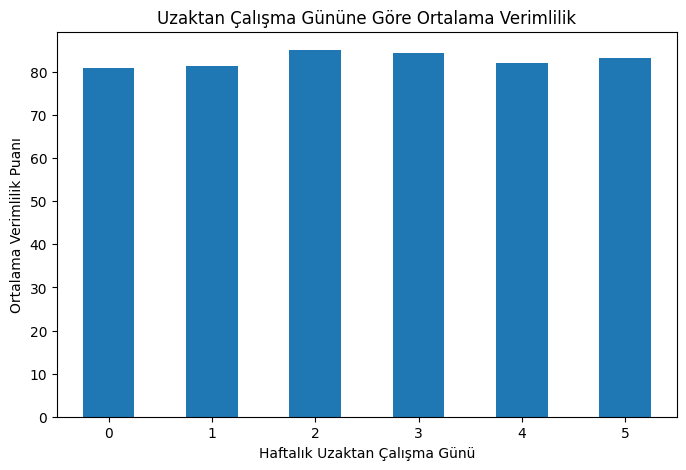

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
verimlilik_analizi.plot(kind="bar")

plt.title("Uzaktan Çalışma Gününe Göre Ortalama Verimlilik")
plt.xlabel("Haftalık Uzaktan Çalışma Günü")
plt.ylabel("Ortalama Verimlilik Puanı")
plt.xticks(rotation=0)
plt.show()

E. Akademik Yorum

Bu araştırmada uzaktan çalışma günleri ile çalışan verimliliği arasındaki ilişki incelenmiştir. Veri setinde toplam 1500 gözlem ve 30 değişken bulunmaktadır. Analiz sonucunda haftada 2 gün uzaktan çalışanların ortalama verimlilik puanı 85,08 ile en yüksek değere ulaşmıştır. Haftada 0 gün uzaktan çalışanların ortalaması 80,86, haftada 5 gün uzaktan çalışanların ortalaması ise 83,22 olarak hesaplanmıştır. Bu sonuçlar, uzaktan çalışma süresi ile verimlilik arasında farklılıklar olduğunu göstermektedir. Ancak bu bulgular tek başına neden-sonuç ilişkisini kanıtlamamaktadır.

Verimlilik puanı toplamı: 124642.29999999999
Verimlilik puanı ortalaması: 83.09486666666666
Grafik ve veri dosyaları kaydedildi.


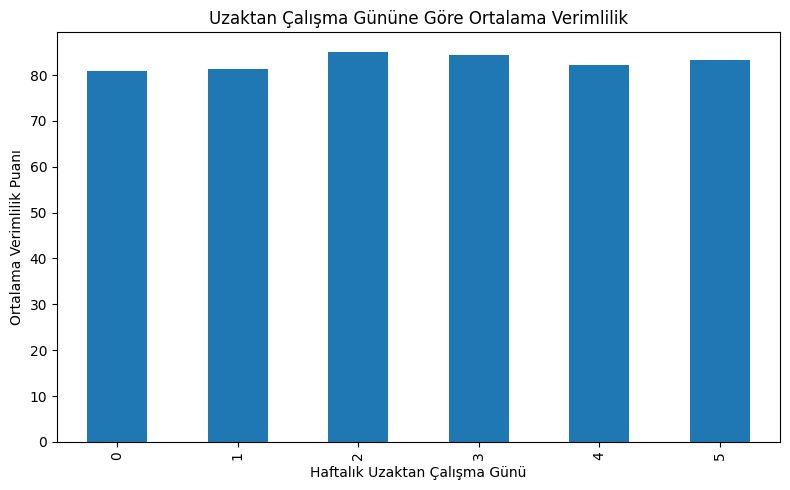

In [24]:
from pathlib import Path
import matplotlib.pyplot as plt

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

print("Verimlilik puanı toplamı:", veri["Productivity_Score"].sum())
print("Verimlilik puanı ortalaması:", veri["Productivity_Score"].mean())

fig, ax = plt.subplots(figsize=(8,5))
verimlilik_analizi.plot(kind="bar", ax=ax)
ax.set_title("Uzaktan Çalışma Gününe Göre Ortalama Verimlilik")
ax.set_xlabel("Haftalık Uzaktan Çalışma Günü")
ax.set_ylabel("Ortalama Verimlilik Puanı")
fig.tight_layout()

fig.savefig(klasor / "grafik.png")
veri.to_csv(klasor / "kullanilan_veri.csv", index=False)

print("Grafik ve veri dosyaları kaydedildi.")